### Universidad Nacional del Centro del Perú (UNCP) — Huancayo, Junín
**Facultad de Ingeniería de Sistemas**

**Curso:** Ingeniería del Conocimiento

**Estudiante:** Espinoza Medina Felipe Reymundo

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

# Ejercicios de Transfer Learning — Feature Extraction
**Ejercicio 1:** Radiografías de tórax (Normal vs Neumonía) con **MobileNetV2**

**Ejercicio 2:** Clasificación de escenas naturales (6 clases) con **EfficientNetB0**

Ambos ejercicios usan *Feature Extraction*: se **congela** el backbone pre-entrenado en ImageNet y solo se entrena un clasificador nuevo encima.

## ⚙️ Configuración del Entorno
Verificamos GPU disponible e instalamos dependencias.

In [1]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

!pip install -q kagglehub

import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score, ConfusionMatrixDisplay)

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

🖥️ GPU detectada: Tesla T4, 15360 MiB
✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 📥 Funciones auxiliares para descargar los datasets de Kaggle
Se usa `kagglehub`, que descarga el dataset directamente a Colab. Si Kaggle pide credenciales, ejecuta `kagglehub.login()` e ingresa tu usuario y token de API (Kaggle → Settings → API → *Create New Token*).

In [2]:
IMG_EXT = ('.jpg', '.jpeg', '.png')

def find_root(base, required):
    """Busca (de forma recursiva) la carpeta que contiene las subcarpetas `required`."""
    for dp, dn, _ in os.walk(base):
        if '__MACOSX' in dp:
            continue
        if all(r in dn for r in required):
            return dp
    raise FileNotFoundError(f"No se encontró una carpeta con {required} dentro de {base}")

def descend(p):
    """Algunos datasets de Kaggle repiten la carpeta (p.ej. seg_train/seg_train). Entra a la interna."""
    inner = os.path.join(p, os.path.basename(p))
    return inner if os.path.isdir(inner) else p

def count_images(folder):
    """Cuenta imágenes por subcarpeta (clase)."""
    return {c: len([f for f in os.listdir(os.path.join(folder, c)) if f.lower().endswith(IMG_EXT)])
            for c in sorted(os.listdir(folder)) if os.path.isdir(os.path.join(folder, c))}

---
# Ejercicio 1 — Básico: Chest X-Ray (Neumonía) con MobileNetV2

**Objetivo:** Primer contacto con Feature Extraction. Clasificación **binaria** (radiografía *NORMAL* vs *PNEUMONIA*) usando MobileNetV2 pre-entrenado en ImageNet.

**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) — 5,856  radiografías de tórax pediátricas (pacientes de 1 a 5 años) en formato JPEG, (5,216 train + 624 test + 16 val).

**¿Por qué MobileNetV2?** Es ligero (~2.2M parámetros en el backbone), rápido y perfecto para empezar.

**Particularidades de este dataset (por eso cambia el enfoque respecto a Cats vs Dogs):**
- **Es un problema médico:** el accuracy no basta. Un *falso negativo* (neumonía no detectada) es mucho más grave que un falso positivo, así que vigilaremos **recall (sensibilidad)**, **precisión**, **especificidad** y **AUC**.
- ⚖️ **Está desbalanceado:** hay aproximadamente 3 radiografías de neumonía por cada 1 normal. Usaremos `class_weight`.
- 🗂️ **La carpeta `val` oficial solo tiene 16 imágenes** (inútil para validar). Se crea una validación propia (20 % de `train`) y se reserva `test` (624 imágenes) para la evaluación final.

### 1.1. Descargar y explorar el dataset

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
📁 Descargado en: /kaggle/input/chest-xray-pneumonia
📁 Raíz del dataset: /kaggle/input/chest-xray-pneumonia/chest_xray


,train (oficial),val (oficial),test (oficial)
NORMAL,1341,8,234
PNEUMONIA,3875,8,390



⚖️ Desbalance en train: 2.89 radiografías de neumonía por cada normal


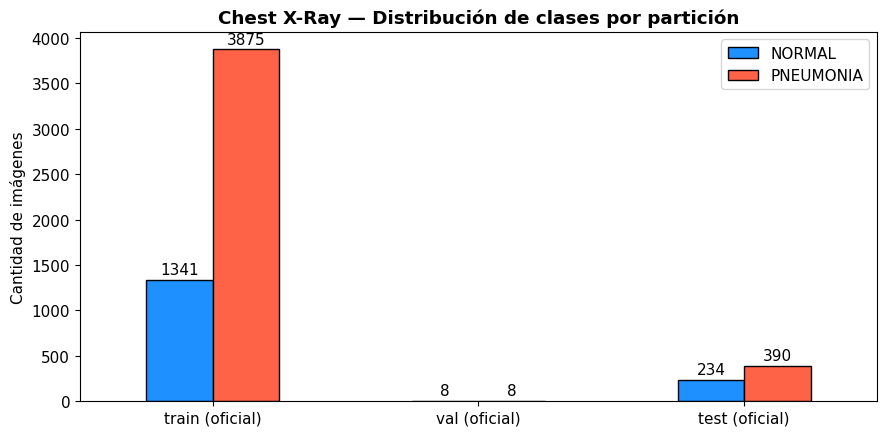

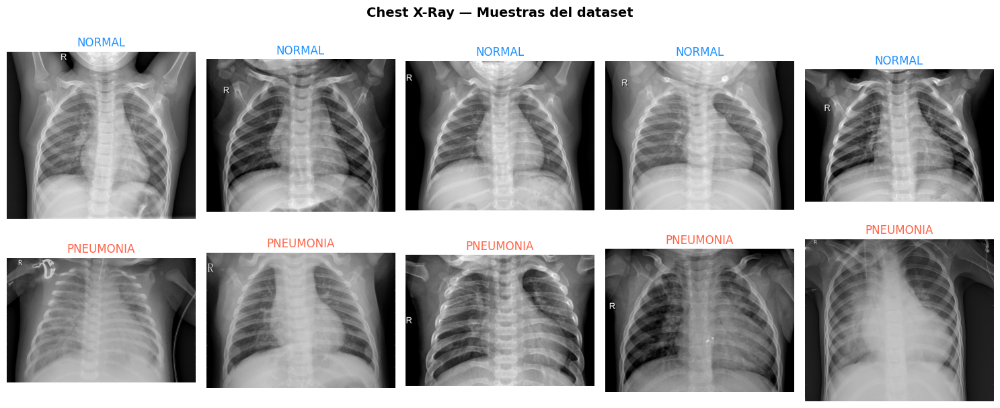

In [3]:
import kagglehub
path_1 = kagglehub.dataset_download('paultimothymooney/chest-xray-pneumonia')
print("📁 Descargado en:", path_1)

ROOT_1      = find_root(path_1, ['train', 'test'])
TRAIN_DIR_1 = os.path.join(ROOT_1, 'train')
TEST_DIR_1  = os.path.join(ROOT_1, 'test')
VAL_DIR_1   = os.path.join(ROOT_1, 'val')   # solo 16 imágenes: NO se usa para validar
print("📁 Raíz del dataset:", ROOT_1)

CLASS_NAMES_1 = ['NORMAL', 'PNEUMONIA']      # NORMAL = 0, PNEUMONIA = 1 (clase positiva)
NUM_CLASSES_1 = len(CLASS_NAMES_1)

conteo = pd.DataFrame({
    'train (oficial)': count_images(TRAIN_DIR_1),
    'val (oficial)':   count_images(VAL_DIR_1),
    'test (oficial)':  count_images(TEST_DIR_1),
})
display(conteo)

n_normal, n_pneu = conteo.loc['NORMAL', 'train (oficial)'], conteo.loc['PNEUMONIA', 'train (oficial)']
print(f"\n⚖️ Desbalance en train: {n_pneu / n_normal:.2f} radiografías de neumonía por cada normal")

# Distribución de clases
fig, ax = plt.subplots(figsize=(9, 4.5))
conteo.T.plot(kind='bar', ax=ax, color=['dodgerblue', 'tomato'], edgecolor='black', rot=0)
for cont in ax.containers:
    ax.bar_label(cont, padding=2)
ax.set_title('Chest X-Ray — Distribución de clases por partición', fontweight='bold')
ax.set_ylabel('Cantidad de imágenes')
plt.tight_layout(); plt.show()

# Visualizar muestras de cada clase
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for r, clase in enumerate(CLASS_NAMES_1):
    carpeta = os.path.join(TRAIN_DIR_1, clase)
    archivos = sorted([f for f in os.listdir(carpeta) if f.lower().endswith(IMG_EXT)])[:5]
    for c, f in enumerate(archivos):
        img = tf.keras.utils.load_img(os.path.join(carpeta, f))
        axes[r, c].imshow(img, cmap='gray')
        axes[r, c].set_title(clase, fontsize=12, color='dodgerblue' if r == 0 else 'tomato')
        axes[r, c].axis('off')
plt.suptitle('Chest X-Ray — Muestras del dataset', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 1.2. Preprocesamiento
MobileNetV2 espera imágenes de **224×224** píxeles. Cada modelo tiene su propio `preprocess_input` que normaliza los píxeles al rango que usó durante su entrenamiento en ImageNet (para MobileNetV2: `[-1, 1]`).

Las radiografías están en escala de grises; `image_dataset_from_directory` las convierte a **3 canales (RGB)** repitiendo el canal, que es lo que exige el backbone.

**Partición de datos:**
| Partición | Origen | Uso |
|---|---|---|
| Train | 80 % de `train` | Entrenar el clasificador |
| Validación | 20 % de `train` | EarlyStopping / monitoreo |
| Test | `test` oficial | Evaluación final (nunca se usa para decidir nada) |


4,173 train, 1,043 validación y 624 test, class_weight real: NORMAL 1,94 y PNEUMONIA 0,67.

> ⚠️ **Detalle técnico importante:** para que `training` y `validation` no se solapen, ambas llamadas deben usar **el mismo `seed` y el mismo valor de `shuffle`**. Por eso las dos llevan `shuffle=True`.

In [4]:
IMG_SIZE_1 = (224, 224)
BATCH_SIZE = 32

def load_split(directory, subset=None, shuffle=False):
    """Carga imágenes desde carpetas. label_mode='binary' → etiqueta 0/1 (sigmoide)."""
    return tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='binary',
        class_names=CLASS_NAMES_1,
        image_size=IMG_SIZE_1,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        validation_split=0.2 if subset else None,
        subset=subset,
    )

# Train y val salen del MISMO directorio con el MISMO seed/shuffle → no se solapan
train_raw_1 = load_split(TRAIN_DIR_1, subset='training',   shuffle=True)
val_raw_1   = load_split(TRAIN_DIR_1, subset='validation', shuffle=True)
# Test: sin mezclar, para que predicciones y etiquetas mantengan el mismo orden
test_raw_1  = load_split(TEST_DIR_1, shuffle=False)

# Función de preprocesamiento
def preprocess_example1(image, label):
    # MobileNetV2 espera píxeles en [-1, 1]
    return tf.keras.applications.mobilenet_v2.preprocess_input(image), label

train_ds_1 = train_raw_1.map(preprocess_example1, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_1   = val_raw_1.map(preprocess_example1,   num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
test_ds_1  = test_raw_1.map(preprocess_example1,  num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# Verificar un batch
for imgs, labels in train_ds_1.take(1):
    print(f"✅ Batch shape: {imgs.shape}")
    print(f"✅ Labels shape: {labels.shape}")
    print(f"✅ Rango de píxeles: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

# Pesos de clase para compensar el desbalance (clase más rara → mayor peso)
total = n_normal + n_pneu
class_weight_1 = {0: total / (2 * n_normal), 1: total / (2 * n_pneu)}
print(f"\n⚖️ class_weight: {{NORMAL: {class_weight_1[0]:.2f}, PNEUMONIA: {class_weight_1[1]:.2f}}}")

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
✅ Batch shape: (32, 224, 224, 3)
✅ Labels shape: (32, 1)
✅ Rango de píxeles: [-1.00, 1.00]

⚖️ class_weight: {NORMAL: 1.94, PNEUMONIA: 0.67}


### 1.3. Construir modelo con Feature Extraction

**Pasos clave:**
1. Cargar MobileNetV2 **sin** el clasificador (`include_top=False`)
2. **Congelar** todas sus capas (`trainable = False`)
3. Agregar nuestro clasificador **binario** (1 neurona con activación **sigmoide**: devuelve P(PNEUMONIA))

In [5]:
from tensorflow.keras import layers, models

# 1. Cargar backbone pre-entrenado (SIN clasificador de ImageNet)
base_model_1 = tf.keras.applications.MobileNetV2(
    weights='imagenet',       # Pesos entrenados en ImageNet
    include_top=False,        # Removemos las capas Dense de 1000 clases
    input_shape=(*IMG_SIZE_1, 3)
)

# 2. CONGELAR todo el backbone
base_model_1.trainable = False

print(f"📐 Backbone: MobileNetV2")
print(f"📐 Capas totales: {len(base_model_1.layers)}")
print(f"📐 Parámetros totales: {base_model_1.count_params():,}")
print(f"📐 Parámetros entrenables: 0  (todo congelado)")
print(f"📐 Output shape: {base_model_1.output_shape}")

# 3. Construir modelo completo: backbone + nuevo clasificador
model_1 = models.Sequential([
    # Backbone congelado
    base_model_1,
    # Nuevo clasificador
    layers.GlobalAveragePooling2D(),             # Reduce 7×7×1280 → 1280
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),       # Binario: P(PNEUMONIA)
], name='chestxray_mobilenetv2_FE')

model_1.summary()

# Contar parámetros
total_p = model_1.count_params()
trainable = sum(tf.size(w).numpy() for w in model_1.trainable_weights)
print(f"\n🔢 Total: {total_p:,} parámetros")
print(f"🔓 Entrenables: {trainable:,} ({trainable/total_p*100:.2f}%)")
print(f"🔒 Congelados: {total_p - trainable:,} ({(total_p-trainable)/total_p*100:.2f}%)")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 Backbone: MobileNetV2
📐 Capas totales: 154
📐 Parámetros totales: 2,257,984
📐 Parámetros entrenables: 0  (todo congelado)
📐 Output shape: (None, 7, 7, 1280)


Model: "chestxray_mobilenetv2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


🔢 Total: 2,259,265 parámetros
🔓 Entrenables: 1,281 (0.06%)
🔒 Congelados: 2,257,984 (99.94%)


### 1.4. Entrenar y evaluar
Además del accuracy se registran **AUC**, **precisión** y **recall**. Se pasa `class_weight` para que los errores sobre la clase minoritaria (NORMAL) pesen más.

In [6]:
# Compilar
model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

# Entrenar (pocas épocas porque Feature Extraction converge rápido)
history_1 = model_1.fit(
    train_ds_1,
    validation_data=val_ds_1,
    epochs=8,
    class_weight=class_weight_1,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True)
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_1.history['val_accuracy']):.4f}")
print(f"🏆 Mejor val_auc:      {max(history_1.history['val_auc']):.4f}")

Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 81s 468ms/step - accuracy: 0.8790 - auc: 0.9546 - loss: 0.3002 - precision: 0.9623 - recall: 0.8702 - val_accuracy: 0.9300 - val_auc: 0.9828 - val_loss: 0.1941 - val_precision: 0.9826 - val_recall: 0.9244
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 37s 283ms/step - accuracy: 0.9372 - auc: 0.9872 - loss: 0.1591 - precision: 0.9839 - recall: 0.9302 - val_accuracy: 0.9511 - val_auc: 0.9880 - val_loss: 0.1419 - val_precision: 0.9818 - val_recall: 0.9534
Epoch 3/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 257ms/step - accuracy: 0.9514 - auc: 0.9903 - loss: 0.1321 - precision: 0.9861 - recall: 0.9474 - val_accuracy: 0.9540 - val_auc: 0.9900 - val_loss: 0.1227 - val_precision: 0.9819 - val_recall: 0.9572
Epoch 4/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 32s 245ms/step - accuracy: 0.9554 - auc: 0.9918 - loss: 0.1186 - precision: 0.9892 - recall: 0.9500 - val_accuracy: 0.9578 - val_auc: 0.9916 - val_loss: 0.1123 - val_precision: 0.9832 - val_recall: 0.9610
Epoch 5/8
131/131 ━━━━━━

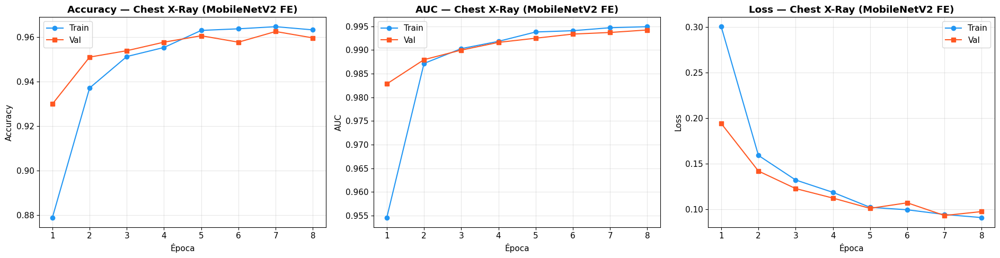

In [7]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
epochs = range(1, len(history_1.history['accuracy']) + 1)

for ax, (met, titulo) in zip(axes, [('accuracy', 'Accuracy'), ('auc', 'AUC'), ('loss', 'Loss')]):
    ax.plot(epochs, history_1.history[met], 'o-', label='Train', color='#2196F3')
    ax.plot(epochs, history_1.history['val_' + met], 's-', label='Val', color='#FF5722')
    ax.set_title(f'{titulo} — Chest X-Ray (MobileNetV2 FE)', fontweight='bold')
    ax.set_xlabel('Época'); ax.set_ylabel(titulo)
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Evaluación final sobre el conjunto de test
El **test oficial** se usa una sola vez, al final. Se analiza con:
- **Matriz de confusión** y *classification report*
- **Sensibilidad (recall de PNEUMONIA):** de los pacientes realmente enfermos, ¿a cuántos detectamos?
- **Especificidad (recall de NORMAL):** de los pacientes sanos, ¿a cuántos descartamos correctamente?
- **Curva ROC / AUC**

📊 Classification Report — Test (Chest X-Ray, MobileNetV2 FE)
              precision    recall  f1-score   support

      NORMAL     0.9605    0.6239    0.7565       234
   PNEUMONIA     0.8136    0.9846    0.8910       390

    accuracy                         0.8494       624
   macro avg     0.8870    0.8043    0.8237       624
weighted avg     0.8687    0.8494    0.8405       624

🩺 Sensibilidad (recall PNEUMONIA): 0.9846   → falsos negativos: 6
🩺 Especificidad (recall NORMAL):   0.6239   → falsos positivos: 88
📈 AUC (test): 0.9631


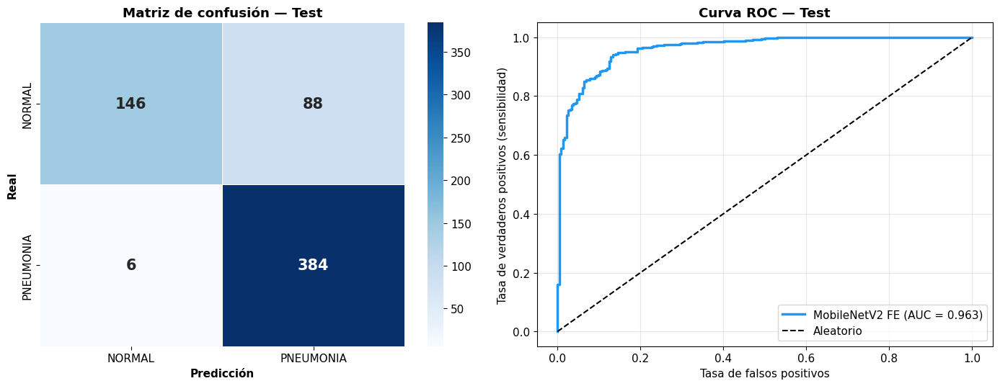

In [8]:
# Predicciones sobre test (test_ds_1 no está mezclado → mismo orden que las etiquetas)
y_true_1 = np.concatenate([y.numpy().ravel() for _, y in test_ds_1]).astype(int)
y_prob_1 = model_1.predict(test_ds_1, verbose=0).ravel()
y_pred_1 = (y_prob_1 >= 0.5).astype(int)

print("📊 Classification Report — Test (Chest X-Ray, MobileNetV2 FE)")
print("=" * 65)
print(classification_report(y_true_1, y_pred_1, target_names=CLASS_NAMES_1, digits=4))

cm_1 = confusion_matrix(y_true_1, y_pred_1)
tn, fp, fn, tp = cm_1.ravel()
sensibilidad = tp / (tp + fn)
especificidad = tn / (tn + fp)
auc_1 = roc_auc_score(y_true_1, y_prob_1)

print(f"🩺 Sensibilidad (recall PNEUMONIA): {sensibilidad:.4f}   → falsos negativos: {fn}")
print(f"🩺 Especificidad (recall NORMAL):   {especificidad:.4f}   → falsos positivos: {fp}")
print(f"📈 AUC (test): {auc_1:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm_1, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES_1,
            yticklabels=CLASS_NAMES_1, ax=axes[0], linewidths=0.5, linecolor='white',
            annot_kws={'size': 15, 'fontweight': 'bold'})
axes[0].set_xlabel('Predicción', fontweight='bold'); axes[0].set_ylabel('Real', fontweight='bold')
axes[0].set_title('Matriz de confusión — Test', fontweight='bold')

fpr, tpr, _ = roc_curve(y_true_1, y_prob_1)
axes[1].plot(fpr, tpr, lw=2.5, color='#2196F3', label=f'MobileNetV2 FE (AUC = {auc_1:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatorio')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Tasa de verdaderos positivos (sensibilidad)')
axes[1].set_title('Curva ROC — Test', fontweight='bold')
axes[1].legend(loc='lower right'); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 1.6. Predicciones visuales

Found 624 files belonging to 2 classes.


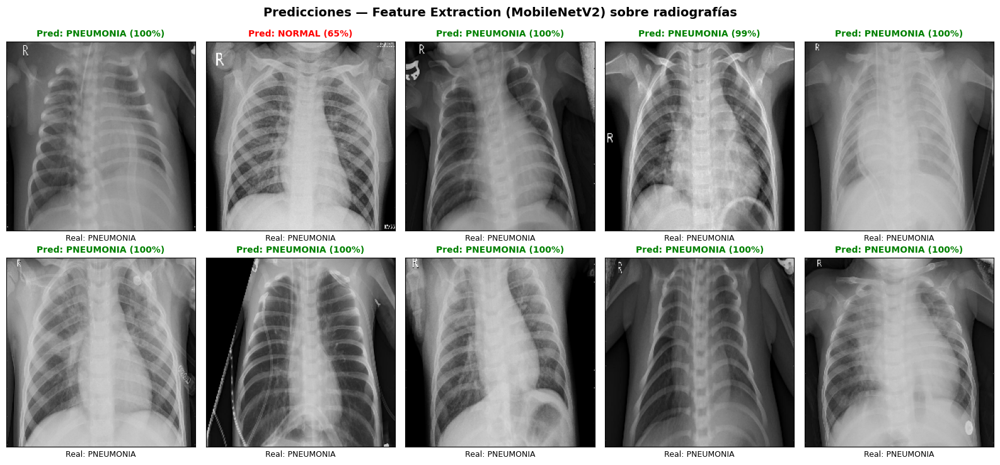

In [9]:
# Muestra aleatoria de test (se carga mezclada solo para visualizar)
vis_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR_1, label_mode='binary', class_names=CLASS_NAMES_1,
    image_size=IMG_SIZE_1, batch_size=10, shuffle=True, seed=7)

for imgs, labels in vis_raw.take(1):
    probs = model_1.predict(tf.keras.applications.mobilenet_v2.preprocess_input(imgs), verbose=0).ravel()

    fig, axes = plt.subplots(2, 5, figsize=(16, 7.5))
    for i in range(10):
        ax = axes[i // 5, i % 5]
        pred_class = CLASS_NAMES_1[int(probs[i] >= 0.5)]
        true_class = CLASS_NAMES_1[int(labels[i].numpy()[0])]
        conf = probs[i] if probs[i] >= 0.5 else 1 - probs[i]
        ax.imshow(imgs[i].numpy().astype('uint8'))
        ax.set_title(f"Pred: {pred_class} ({conf:.0%})", fontsize=10,
                     color='green' if pred_class == true_class else 'red', fontweight='bold')
        ax.set_xlabel(f"Real: {true_class}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Predicciones — Feature Extraction (MobileNetV2) sobre radiografías', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### ✅ Conclusión Ejemplo 1



In [10]:
resumen_1 = pd.DataFrame({
    'Valor': {
        'Modelo base':                'MobileNetV2 (ImageNet, congelado)',
        'Parámetros del backbone':    f'{base_model_1.count_params():,}',
        'Parámetros entrenados':      f'{trainable:,} (solo el clasificador)',
        'Épocas ejecutadas':          len(history_1.history['loss']),
        'Mejor Val Accuracy':         f"{max(history_1.history['val_accuracy']):.4f}",
        'Test Accuracy':              f"{(y_true_1 == y_pred_1).mean():.4f}",
        'Test AUC':                   f"{auc_1:.4f}",
        'Test Sensibilidad (PNEUMONIA)': f"{sensibilidad:.4f}",
        'Test Especificidad (NORMAL)':   f"{especificidad:.4f}",
    }
})
display(resumen_1)

,Valor
Modelo base,"MobileNetV2 (ImageNet, congelado)"
Parámetros del backbone,"2,257,984"
Parámetros entrenados,"1,281 (solo el clasificador)"
Épocas ejecutadas,8
Mejor Val Accuracy,0.9626
Test Accuracy,0.8494
Test AUC,0.9631
Test Sensibilidad (PNEUMONIA),0.9846
Test Especificidad (NORMAL),0.6239


Con Feature Extraction se entrenaron solo 1,281 parámetros y MobileNetV2 alcanzó 96,26 % de accuracy y 0,994 de AUC en validación, en pocos minutos. En el test oficial el accuracy bajó a 84,9 %, aunque el AUC se mantuvo alto (0,963).

El modelo prioriza detectar la enfermedad: la sensibilidad es de 98,5 % (solo 6 de 390 casos de neumonía sin detectar). A cambio, la especificidad es de solo 62,4 %: 88 de 234 radiografías normales se clasificaron como neumonía. Esto es aceptable en un cribado médico, donde un falso negativo es más grave que un falso positivo. Sin embargo, produciría muchas falsas alarmas.

La diferencia entre validación (96 %) y test (85 %) indica un cambio de distribución entre ambas particiones. Además, la validación sale del mismo train, y es posible que haya imágenes del mismo paciente repartidas entre ambos conjuntos, lo que la vuelve optimista. Como el AUC sigue alto, el modelo sí separa bien las clases. El problema está en que el umbral de 0,5 no está calibrado para el test, así que se podría ajustar.

Limitaciones: ImageNet contiene fotos naturales y no radiografías (domain gap). El modelo no es una herramienta de diagnóstico. Mejoras: ajustar el umbral de decisión, hacer Fine-Tuning de las últimas capas y separar train/validación por paciente.

---
# Ejercicio 2 — Intermedio: Intel Image Classification con EfficientNetB0

**Objetivo:** Feature Extraction con **6 clases**, EDA detallado, Data Augmentation, métricas avanzadas (confusion matrix, classification report) y visualización de feature maps.

**Dataset:** [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) —> 25,000 imágenes de **150×150** píxeles de escenas naturales, en 6 clases: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`. Viene dividido en `seg_train` (14,034), `seg_test` (3,000) , `val`(2806) (20 % de train) y `seg_pred` (7,000 sin etiquetas, que no usaremos).

**¿Por qué EfficientNetB0?** Mejor balance accuracy/eficiencia de su generación. Un "upgrade" natural sobre MobileNetV2.

**Particularidades de este dataset:**
- 🏞️ Hay clases visualmente parecidas (**glacier ↔ mountain**, **buildings ↔ street**), por lo que se espera que las confusiones se concentren ahí.
- 🔍 Las imágenes son de 150×150 y el backbone espera 224×224, así que se **reescalan hacia arriba**.

### 2.1. Descargar el dataset y EDA

Using Colab cache for faster access to the 'intel-image-classification' dataset.
📁 Descargado en: /kaggle/input/intel-image-classification
📁 Train: /kaggle/input/intel-image-classification/seg_train/seg_train
📁 Test:  /kaggle/input/intel-image-classification/seg_test/seg_test

🏞️ Clases (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


,train (seg_train),test (seg_test)
buildings,2191,437
forest,2271,474
glacier,2404,553
mountain,2512,525
sea,2274,510
street,2382,501


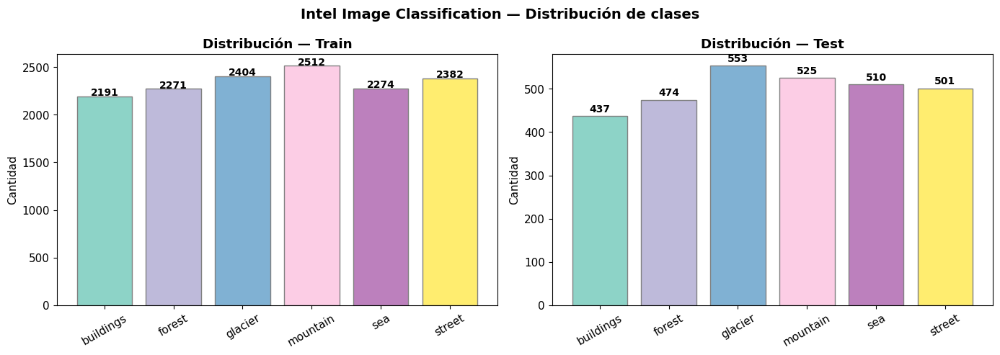

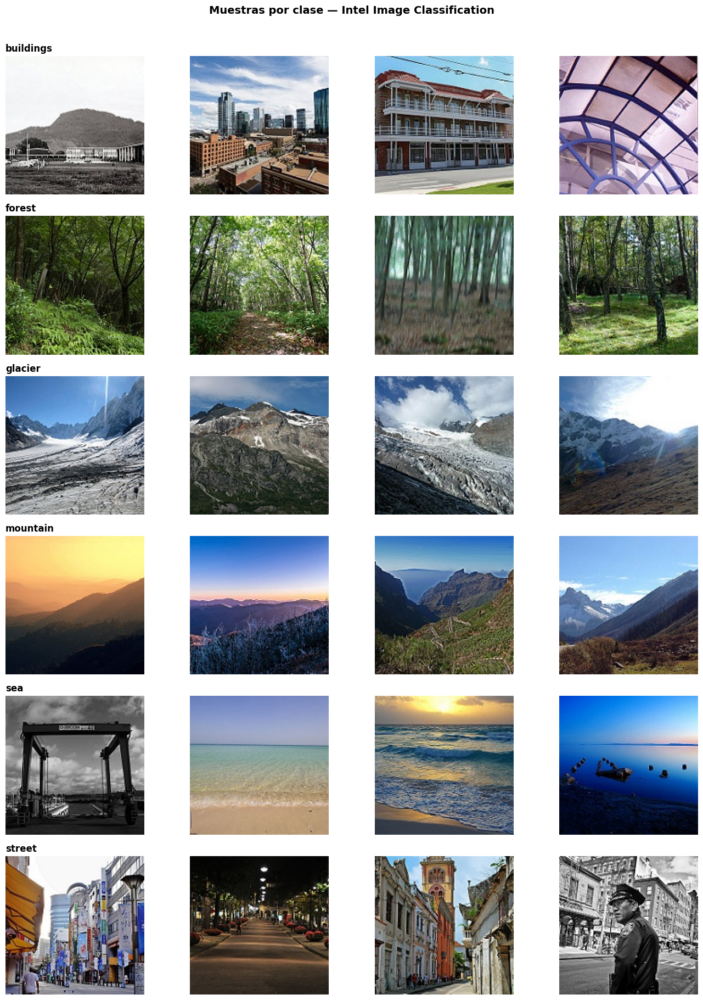

In [11]:
path_2 = kagglehub.dataset_download('puneet6060/intel-image-classification')
print("📁 Descargado en:", path_2)

ROOT_2      = find_root(path_2, ['seg_train', 'seg_test'])
TRAIN_DIR_2 = descend(os.path.join(ROOT_2, 'seg_train'))
TEST_DIR_2  = descend(os.path.join(ROOT_2, 'seg_test'))
print("📁 Train:", TRAIN_DIR_2)
print("📁 Test: ", TEST_DIR_2)

conteo_2 = pd.DataFrame({'train (seg_train)': count_images(TRAIN_DIR_2),
                         'test (seg_test)':   count_images(TEST_DIR_2)})
CLASS_NAMES_2 = list(conteo_2.index)          # orden alfabético (el mismo que usa Keras)
NUM_CLASSES_2 = len(CLASS_NAMES_2)
print(f"\n🏞️ Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
display(conteo_2)

# Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))
for ax, col, title_str in [(axes[0], 'train (seg_train)', 'Train'), (axes[1], 'test (seg_test)', 'Test')]:
    bars = ax.bar(conteo_2.index, conteo_2[col], color=colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    for bar, count in zip(bars, conteo_2[col]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
               str(count), ha='center', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Intel Image Classification — Distribución de clases', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

# Muestras por clase
fig, axes = plt.subplots(NUM_CLASSES_2, 4, figsize=(14, 3 * NUM_CLASSES_2))
for class_idx, clase in enumerate(CLASS_NAMES_2):
    carpeta = os.path.join(TRAIN_DIR_2, clase)
    archivos = sorted([f for f in os.listdir(carpeta) if f.lower().endswith(IMG_EXT)])[:4]
    for col, f in enumerate(archivos):
        ax = axes[class_idx, col]
        ax.imshow(tf.keras.utils.load_img(os.path.join(carpeta, f)))
        ax.axis('off')
        if col == 0:
            ax.set_title(clase, fontsize=12, fontweight='bold', loc='left')
plt.suptitle('Muestras por clase — Intel Image Classification', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

### 2.2. Preprocesamiento con Data Augmentation

Para mejorar la generalización, aplicamos **Data Augmentation solo durante el entrenamiento**. Aquí las capas de augmentation se incluyen **dentro del modelo**: Keras las activa únicamente en `fit()` y las desactiva automáticamente en `predict()`/`evaluate()`, por lo que no hace falta mantener dos pipelines distintos.

EfficientNet (en Keras) ya incluye internamente su capa de reescalado, así que recibe los píxeles en el rango **[0, 255]** sin necesidad de `preprocess_input` adicional.

**Partición:** 80 % de `seg_train` para entrenar, 20 % para validar y `seg_test` como test final.

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
✅ Pipelines listos (augmentation incluida dentro del modelo)


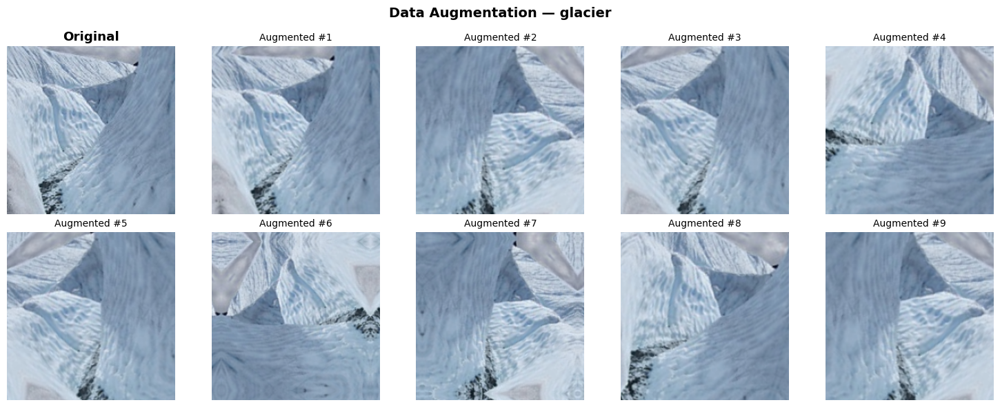

In [12]:
IMG_SIZE_2 = (224, 224)

def load_split_2(directory, subset=None, shuffle=False):
    return tf.keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='categorical',        # one-hot, para softmax + categorical_crossentropy
        class_names=CLASS_NAMES_2,
        image_size=IMG_SIZE_2,           # reescala 150×150 → 224×224
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        validation_split=0.2 if subset else None,
        subset=subset,
    )

# Mismo seed y shuffle en train/val → particiones disjuntas
train_raw_2 = load_split_2(TRAIN_DIR_2, subset='training',   shuffle=True)
val_raw_2   = load_split_2(TRAIN_DIR_2, subset='validation', shuffle=True)
test_raw_2  = load_split_2(TEST_DIR_2, shuffle=False)

train_ds_2 = train_raw_2.prefetch(tf.data.AUTOTUNE)
val_ds_2   = val_raw_2.prefetch(tf.data.AUTOTUNE)
test_ds_2  = test_raw_2.prefetch(tf.data.AUTOTUNE)

# Capa de augmentation (solo se activa en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='augmentation')

print("✅ Pipelines listos (augmentation incluida dentro del modelo)")

# Visualizar augmentation
for imgs, labels in train_raw_2.take(1):
    sample_img = imgs[0]
    sample_name = CLASS_NAMES_2[int(np.argmax(labels[0].numpy()))]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(sample_img.numpy().astype('uint8'))
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    augmented = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
    ax.imshow(np.clip(augmented[0].numpy(), 0, 255).astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — {sample_name}', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.3. Construir modelo con EfficientNetB0

In [13]:
# Backbone EfficientNetB0
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)
base_model_2.trainable = False  # Congelar

# Modelo con clasificador más robusto
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = data_augmentation(inputs_2)             # Solo activa durante el entrenamiento
x = base_model_2(x, training=False)         # BN del backbone en modo inferencia
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='intel_efficientnetb0_FE')

# Resumen
total_2 = model_2.count_params()
trainable_2 = sum(tf.size(w).numpy() for w in model_2.trainable_weights)
print(f"📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total_2:,} | 🔓 Entrenables: {trainable_2:,} | 🔒 Congelados: {total_2-trainable_2:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,219,433 | 🔓 Entrenables: 167,302 | 🔒 Congelados: 4,052,131


### 2.4. Entrenar con callbacks profesionales
- `EarlyStopping`: detiene el entrenamiento cuando `val_loss` deja de mejorar y restaura los mejores pesos.
- `ReduceLROnPlateau`: reduce a la mitad el learning rate cuando `val_loss` se estanca.

In [14]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - accuracy: 0.8218 - loss: 0.5162 - val_accuracy: 0.9141 - val_loss: 0.2318 - learning_rate: 0.0010
Epoch 2/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 96ms/step - accuracy: 0.8720 - loss: 0.3659 - val_accuracy: 0.9234 - val_loss: 0.2144 - learning_rate: 0.0010
Epoch 3/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - accuracy: 0.8815 - loss: 0.3178 - val_accuracy: 0.9141 - val_loss: 0.2461 - learning_rate: 0.0010
Epoch 4/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8835 - loss: 0.3129
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
351/351 ━━━━━━━━━━━━━━━━━━━━ 33s 95ms/step - accuracy: 0.8836 - loss: 0.3106 - val_accuracy: 0.9216 - val_loss: 0.2194 - learning_rate: 0.0010
Epoch 5/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 96ms/step - accuracy: 0.8943 - loss: 0.2850 - val_accuracy: 0.9259 - val_loss: 0.2083 - learning_rate: 5.0000e-04
Epoch 6/15
351/351 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - accuracy: 0.897

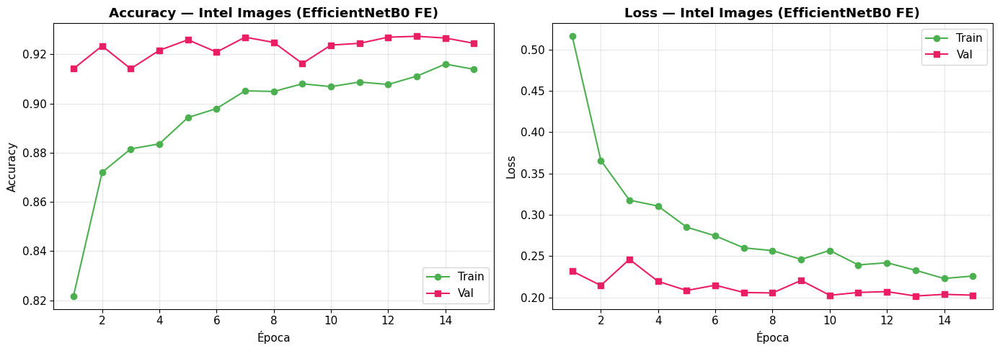

In [15]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, len(history_2.history['accuracy']) + 1)
axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title('Accuracy — Intel Images (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title('Loss — Intel Images (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.5. Evaluación detallada sobre Test: Confusion Matrix + Classification Report
La evaluación final se hace sobre `seg_test` (datos que el modelo nunca vio ni usó para ajustar nada).

🎯 Test accuracy: 0.9217

📊 Classification Report — Intel Images, Test (EfficientNetB0 FE)
              precision    recall  f1-score   support

   buildings     0.9368    0.9153    0.9259       437
      forest     0.9958    0.9937    0.9947       474
     glacier     0.8651    0.8698    0.8674       553
    mountain     0.8973    0.8324    0.8636       525
         sea     0.9193    0.9824    0.9498       510
      street     0.9277    0.9481    0.9378       501

    accuracy                         0.9217      3000
   macro avg     0.9237    0.9236    0.9232      3000
weighted avg     0.9215    0.9217    0.9212      3000



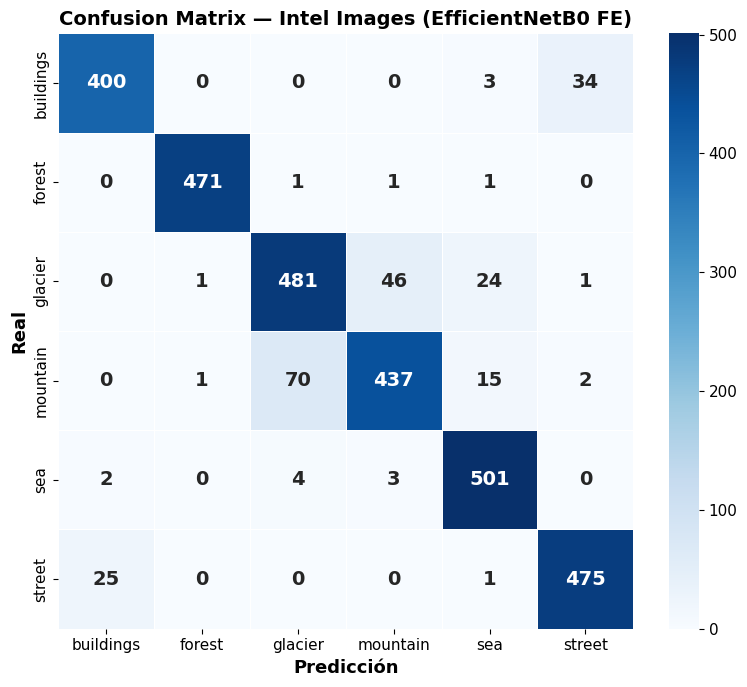


🔍 Principales confusiones (Real → Predicho):
   mountain → glacier: 70 errores
   glacier → mountain: 46 errores
   buildings → street: 34 errores
   street → buildings: 25 errores
   glacier → sea: 24 errores
   mountain → sea: 15 errores


In [16]:
# Obtener predicciones (test_ds_2 no está mezclado → mismo orden que las etiquetas)
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds_2])
y_prob_2 = model_2.predict(test_ds_2, verbose=0)
y_pred = np.argmax(y_prob_2, axis=1)

print(f"🎯 Test accuracy: {(y_true == y_pred).mean():.4f}\n")

# Classification Report
print("📊 Classification Report — Intel Images, Test (EfficientNetB0 FE)")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES_2, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2, ax=ax,
           linewidths=0.5, linecolor='white',
           annot_kws={'size': 14, 'fontweight': 'bold'})

ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — Intel Images (EfficientNetB0 FE)',
            fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top errores (se ordenan de mayor a menor)
print("\n🔍 Principales confusiones (Real → Predicho):")
errores = [(CLASS_NAMES_2[i], CLASS_NAMES_2[j], cm[i, j])
           for i in range(NUM_CLASSES_2) for j in range(NUM_CLASSES_2) if i != j and cm[i, j] > 5]
for real, pred, n in sorted(errores, key=lambda t: -t[2]):
    print(f"   {real} → {pred}: {n} errores")

### 2.6. Visualización de errores
Ver **qué imágenes** se equivocan ayuda a entender si el modelo falla por un defecto real o porque la imagen es ambigua (por ejemplo, una calle con edificios al fondo).

❌ Imágenes mal clasificadas: 235 de 3000


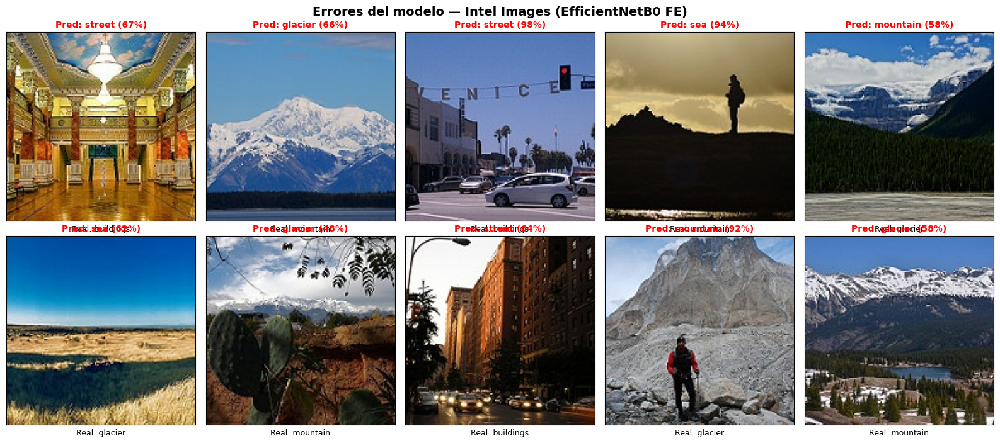

In [17]:
# Recuperar las imágenes de test mal clasificadas (mismo orden que y_true / y_pred)
rutas_test = np.array(test_raw_2.file_paths)
idx_err = np.where(y_true != y_pred)[0]
print(f"❌ Imágenes mal clasificadas: {len(idx_err)} de {len(y_true)}")

rng = np.random.default_rng(SEED)
muestra = rng.choice(idx_err, size=min(10, len(idx_err)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, i in zip(axes.ravel(), muestra):
    ax.imshow(tf.keras.utils.load_img(rutas_test[i]))
    ax.set_title(f"Pred: {CLASS_NAMES_2[y_pred[i]]} ({y_prob_2[i].max():.0%})", color='red',
                 fontsize=10, fontweight='bold')
    ax.set_xlabel(f"Real: {CLASS_NAMES_2[y_true[i]]}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Errores del modelo — Intel Images (EfficientNetB0 FE)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.7. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0 en nuestras escenas? Extraemos los mapas de activación de capas clave: las primeras capas detectan bordes y texturas, y las profundas, patrones más abstractos.

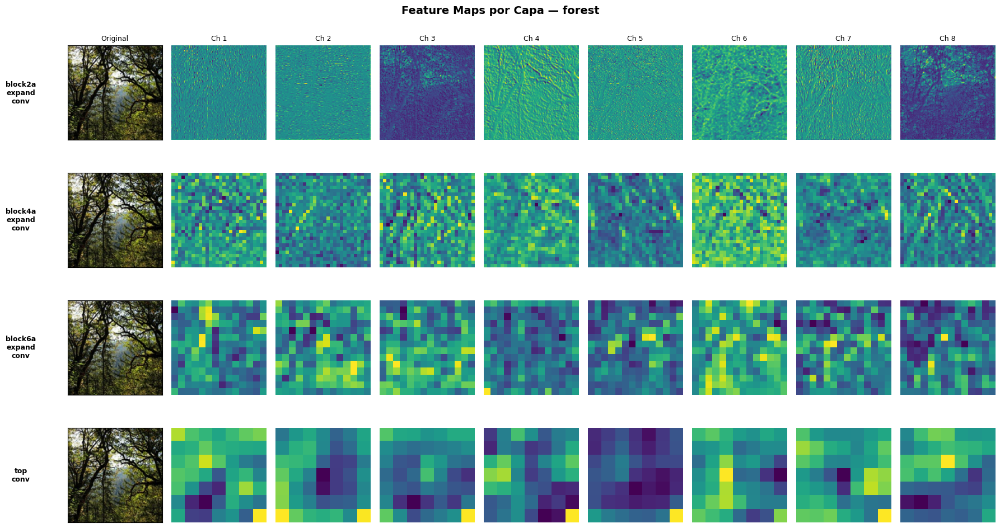

In [18]:
# Seleccionar capas para visualizar
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [
    models.Model(inputs=base_model_2.input,
                outputs=base_model_2.get_layer(name).output)
    for name in layer_names
]

# Tomar una imagen de ejemplo del conjunto de validación (rango 0-255, igual que espera el backbone)
for imgs, labels in val_raw_2.take(1):
    sample_img_raw = imgs[0]
    sample_name_raw = CLASS_NAMES_2[int(np.argmax(labels[0].numpy()))]
sample_batch = tf.expand_dims(sample_img_raw, 0)

# Extraer features
fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))

for row, (feat_model, layer_name) in enumerate(zip(feature_models, layer_names)):
    features = feat_model.predict(sample_batch, verbose=0)
    # Mostrar la imagen original en la primera columna
    axes[row, 0].imshow(sample_img_raw.numpy().astype('uint8'))
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(layer_name.replace('_', '\n'), fontsize=9,
                           fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    # Mostrar 8 feature maps
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < features.shape[-1]:
            ax.imshow(features[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por Capa — {sample_name_raw}',
            fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### ✅ Conclusión Ejercicio 2



In [19]:
from sklearn.metrics import f1_score
f1_por_clase = f1_score(y_true, y_pred, average=None)

resumen_2 = pd.DataFrame({
    'Valor': {
        'Modelo base':               'EfficientNetB0 (ImageNet, congelado)',
        'Parámetros del backbone':   f'{base_model_2.count_params():,}',
        'Parámetros entrenados':     f'{trainable_2:,} (solo el head)',
        'Épocas ejecutadas':         len(history_2.history['loss']),
        'Mejor Val Accuracy':        f"{max(history_2.history['val_accuracy']):.4f}",
        'Test Accuracy':             f"{(y_true == y_pred).mean():.4f}",
        'Test F1 macro':             f"{f1_score(y_true, y_pred, average='macro'):.4f}",
        'Clase con mejor F1':        f"{CLASS_NAMES_2[int(np.argmax(f1_por_clase))]} ({f1_por_clase.max():.3f})",
        'Clase con peor F1':         f"{CLASS_NAMES_2[int(np.argmin(f1_por_clase))]} ({f1_por_clase.min():.3f})",
        'Augmentation':              'Flip + Rotation + Zoom + Contrast',
    }
})
display(resumen_2)

,Valor
Modelo base,"EfficientNetB0 (ImageNet, congelado)"
Parámetros del backbone,"4,049,571"
Parámetros entrenados,"167,302 (solo el head)"
Épocas ejecutadas,15
Mejor Val Accuracy,0.9273
Test Accuracy,0.9217
Test F1 macro,0.9232
Clase con mejor F1,forest (0.995)
Clase con peor F1,mountain (0.864)
Augmentation,Flip + Rotation + Zoom + Contrast


Con solo 167,302 parámetros entrenables, EfficientNetB0 congelado alcanzó 92,2 % de accuracy y 0,923 de F1 macro en el test oficial (3,000 imágenes). Esto es casi igual al 92,7 % de validación, por lo que el modelo generaliza bien.

Durante el entrenamiento, la accuracy de train (~91 %) quedó ligeramente por debajo de la de validación (~92,5 %). Esto es normal: el Dropout y el Data Augmentation solo están activos al entrenar, lo que dificulta un poco el train. La validación se estancó cerca de 0,20 de loss, y el ReduceLROnPlateau redujo el learning rate dos veces. Esto indica que el head congelado ya aprovechó casi todo lo que puede dar el backbone.

Forest es la clase más fácil (F1 0,995). Los errores se concentran en clases visualmente parecidas: mountain ↔ glacier (116 errores entre ambas direcciones) y buildings ↔ street (59). También hay confusiones menores entre glacier/mountain y sea. Esto cuadra con la sección 2.6, donde varias imágenes mal clasificadas son ambiguas, con varias escenas en una sola foto.

Mejora: Fine-Tuning de los últimos bloques del backbone con un learning rate bajo (~1e-5).

---
#  Comparación final de ambos ejemplos

| | Ejemplo 1 | Ejemplo 2 |
|---|---|---|
| **Dataset** | Chest X-Ray (Neumonía) | Intel Image Classification |
| **Tipo de problema** | Binario, desbalanceado, médico | Multiclase (6), balanceado |
| **Backbone** | MobileNetV2 | EfficientNetB0 |
| **Salida / pérdida** | Sigmoide + `binary_crossentropy` | Softmax + `categorical_crossentropy` |
| **Técnicas clave** | `class_weight`, sensibilidad/especificidad, ROC | Data Augmentation, matriz de confusión, feature maps |
| **Métrica prioritaria** | Sensibilidad / AUC | Accuracy / F1 macro |